<a href="https://colab.research.google.com/github/paulc02/ML-Seminar-CalamusaSalvatore/blob/main/Calamusa_Salvatore_Tema_LP3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [2]:
# TODO 1.1 — procentul de valori lipsă pe coloană
missing_percent = (df.isnull().sum() / len(df)) * 100
print("Procentul de valori lipsa pentru fiecare coloana sortat descrescator:")
print(missing_percent.sort_values(ascending=False))

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
cols_to_drop = missing_percent[missing_percent > 50].index
print(f"\nColoanele eliminate: {list(cols_to_drop)}")

df = df.drop(columns=cols_to_drop)
df.head()

Procentul de valori lipsa pentru fiecare coloana sortat descrescator:
deck        77.216611
age         19.865320
embarked     0.224467
sex          0.000000
pclass       0.000000
survived     0.000000
fare         0.000000
dtype: float64

Coloanele eliminate: ['deck']


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [3]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()

df['age'] = df['age'].fillna(df['age'].median())

most_frequent_embarked = df['embarked'].mode()[0]
df['embarked'] = df['embarked'].fillna(most_frequent_embarked)

# TODO 2.2 — verificare + comparație deviație standard
print("Valori lipsa ramase pentru fiecare coloana:")
print(df.isnull().sum())

print(f"\nAbaterea standard a lui 'age' inainte de imputare: {age_inainte.std():.4f}")
print(f"Abaterea standard 'age' dupa imputare: {df['age'].std():.4f}")

Valori lipsa ramase pentru fiecare coloana:
survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64

Abaterea standard a lui 'age' inainte de imputare: 14.5265
Abaterea standard 'age' dupa imputare: 13.0197


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness-ul initial pentru 'fare': 4.7873
Skewness-ul dupa transformarea logaritmica: 0.3949


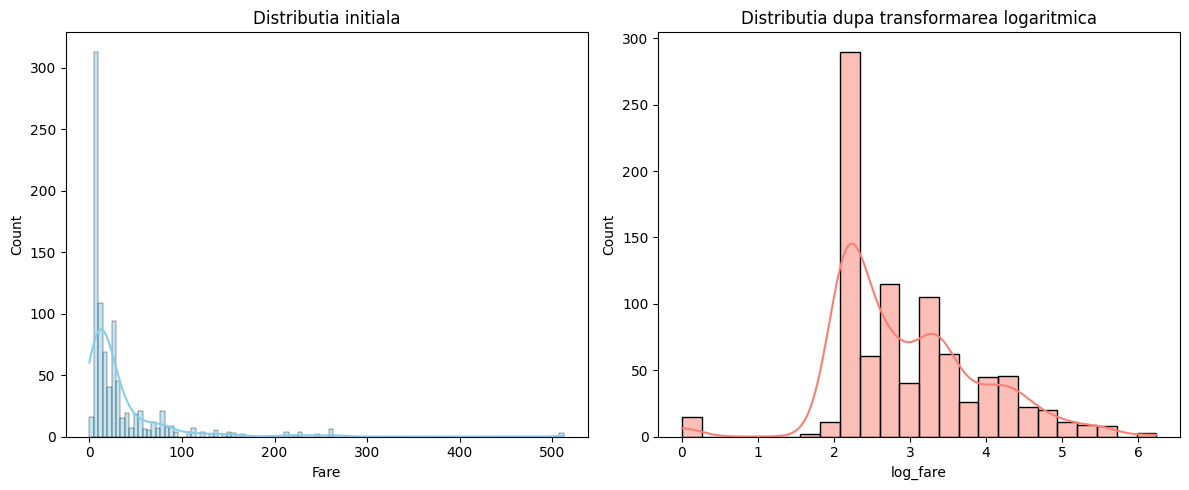

In [7]:
# TODO 3.1 — skewness fare
skew_fare = df['fare'].skew()
print(f"Skewness-ul initial pentru 'fare': {skew_fare:.4f}")

# TODO 3.2 — coloana log_fare + skewness
df['log_fare'] = np.log1p(df['fare'])
skew_log_fare = df['log_fare'].skew()
print(f"Skewness-ul dupa transformarea logaritmica: {skew_log_fare:.4f}")

# TODO 3.3 — două histograme
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['fare'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title(f"Distributia initiala")
axes[0].set_xlabel("Fare")

sns.histplot(df['log_fare'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title(f"Distributia dupa transformarea logaritmica")
axes[1].set_xlabel("Log(Fare + 1)")

plt.tight_layout()
plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [5]:
# TODO 4.1 — limite IQR + număr de outlieri
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df['fare'] < lower_limit) | (df['fare'] > upper_limit)]
print(f"Limitele IQR: [{lower_limit:.4f} ; {upper_limit:.4f}]")
print(f"Numarul de outlieri identificati: {len(outliers)}")

# TODO 4.2 — fare_capped (clip) + maxim înainte/după
df['fare_capped'] = df['fare'].clip(lower=lower_limit, upper=upper_limit)

print(f"\nValoarea maxima inainte de clip: {df['fare'].max():.4f}")
print(f"Valoarea maxima dupa clip: {df['fare_capped'].max():.4f}")

Limitele IQR: [-26.7240 ; 65.6344]
Numarul de outlieri identificati: 116

Valoarea maxima inainte de clip: 512.3292
Valoarea maxima dupa clip: 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [6]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
cols_to_encode = [col for col in ['sex', 'embarked'] if col in df.columns]
if cols_to_encode:
    df = pd.get_dummies(df, columns=cols_to_encode, drop_first=True, dtype=int)

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scaler = StandardScaler()
df[['age', 'fare_capped']] = scaler.fit_transform(df[['age', 'fare_capped']])

print("Verificare medie:")
print(df[['age', 'fare_capped']].mean())

print("\nVerificare abatere standard:")
print(df[['age', 'fare_capped']].std())

print("\nPrimele randuri din setul de date:")
df.head()

Verificare medie:
age            2.272780e-16
fare_capped    9.968332e-17
dtype: float64

Verificare abatere standard:
age            1.000562
fare_capped    1.000562
dtype: float64

Primele randuri din setul de date:


,survived,pclass,age,fare,log_fare,fare_capped,sex_male,embarked_Q,embarked_S
0,0,3,-0.565736,7.2500,2.110213,-0.820552,1,0,1
1,1,1,0.663861,71.2833,4.280593,2.031623,0,0,0
2,1,3,-0.258337,7.9250,2.188856,-0.787578,0,0,1
3,1,1,0.433312,53.1000,3.990834,1.419297,0,0,1
4,0,3,0.433312,8.0500,2.202765,-0.781471,1,0,1


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:*